In [1]:
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt

In [2]:
import seaborn as sns

In [3]:
df = pd.read_csv(r"homework_2_files/car_fuel_efficiency_2026.csv")

In [4]:
df

,model_year,origin,fuel_type,drivetrain,num_doors,engine_displacement,num_cylinders,horsepower,vehicle_weight,acceleration,fuel_efficiency_mpg
0,2006,Europe,Gasoline,Front-wheel drive,4,2180,6,243.0,3870,NaN,31.9
1,2008,Europe,Diesel,Front-wheel drive,4,2390,6,272.0,4210,NaN,31.3
2,1996,Asia,Gasoline,Front-wheel drive,5,2320,6,267.0,4240,17.3,27.5
3,1989,Europe,Gasoline,Front-wheel drive,4,2130,6,258.0,4490,18.7,28.5
4,1994,USA,Diesel,Front-wheel drive,3,2580,7,304.0,4510,17.5,31.0
...,...,...,...,...,...,...,...,...,...,...,...
9995,2005,USA,Gasoline,All-wheel drive,4,2470,6,271.0,4690,18.9,27.4
9996,1993,Asia,Gasoline,All-wheel drive,2,2300,6,244.0,4370,19.0,30.0
9997,2014,USA,Gasoline,All-wheel drive,3,2480,6,267.0,4590,18.4,28.1
9998,2004,USA,Hybrid,Rear-wheel drive,5,2180,6,270.0,4450,20.9,32.2


## Preparing the dataset

In [5]:
df = df[['engine_displacement',
'horsepower',
'vehicle_weight',
'model_year',
'fuel_efficiency_mpg']]

In [6]:
df

,engine_displacement,horsepower,vehicle_weight,model_year,fuel_efficiency_mpg
0,2180,243.0,3870,2006,31.9
1,2390,272.0,4210,2008,31.3
2,2320,267.0,4240,1996,27.5
3,2130,258.0,4490,1989,28.5
4,2580,304.0,4510,1994,31.0
...,...,...,...,...,...
9995,2470,271.0,4690,2005,27.4
9996,2300,244.0,4370,1993,30.0
9997,2480,267.0,4590,2014,28.1
9998,2180,270.0,4450,2004,32.2


## EDA

<Axes: xlabel='fuel_efficiency_mpg', ylabel='Count'>

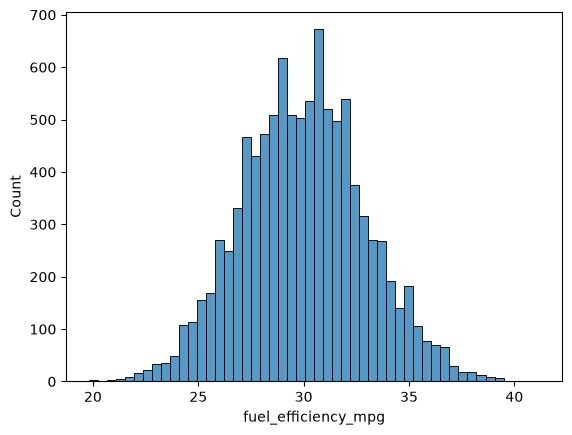

In [7]:
sns.histplot(df['fuel_efficiency_mpg'], bins = 50)

It does not have a long tail

## Question 1

In [8]:
result = df[['engine_displacement',
'horsepower',
'vehicle_weight',
'model_year']].isna().any()

print(result[result==True].index.tolist())

['horsepower']


## Question 2

'horsepower' is the column with missing value.

In [9]:
df['horsepower'].median()

np.float64(254.0)

254

### Shuffle and split

In [10]:
n = len(df)
n_val = int(n * 0.2)
n_test = int(n * 0.2)
n_train = n - n_val - n_test

np.random.seed(42)
idx = np.arange(n)
np.random.shuffle(idx)

df_train = df.iloc[idx[:n_train]]
df_val = df.iloc[idx[n_train:n_train + n_val]]
df_test = df.iloc[idx[n_train + n_val:]]

In [11]:
len(df_train), len(df_val), len(df_test)

(6000, 2000, 2000)

## Question 3

In [12]:
df_train_zero_fill = df_train.fillna(0)
df_train_mean_fill = df_train.fillna(df['horsepower'].mean())

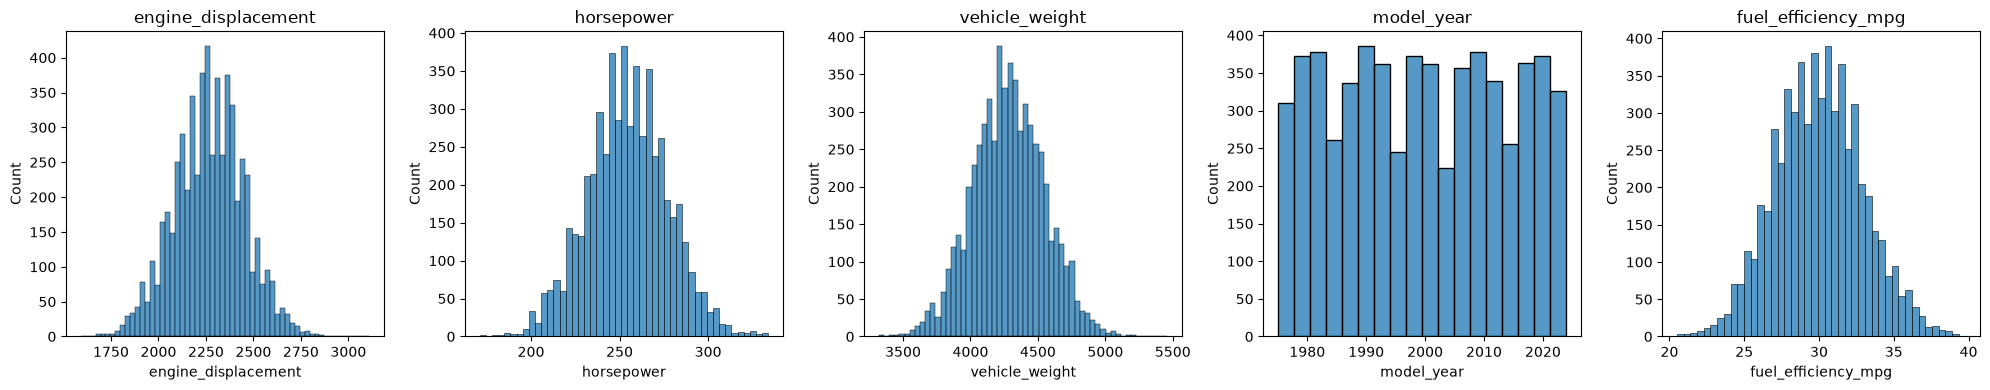

In [13]:
fig, axes = plt.subplots(1, 5, figsize=(20, 4))

for ax, col in zip(axes, df_train.columns[:5]):
    sns.histplot(df_train[col], ax=ax)
    ax.set_title(col)

plt.tight_layout()
plt.show()

In [14]:
# we're predicting fuel efficiency

# updated : removed np.log1p

y_train = (df_train.fuel_efficiency_mpg.values)
y_val = (df_val.fuel_efficiency_mpg.values)
y_test = (df_test.fuel_efficiency_mpg.values)

In [15]:
del df_train['fuel_efficiency_mpg']
del df_val['fuel_efficiency_mpg']
del df_test['fuel_efficiency_mpg']

In [16]:
def train_linear_regression(X, y):
    ones = np.ones(X.shape[0])
    X = np.column_stack([ones, X])

    XTX = X.T.dot(X)
    XTX_inv = np.linalg.inv(XTX)
    w_full = XTX_inv.dot(X.T).dot(y)

    return w_full[0], w_full[1:]

In [17]:
def rmse(y, y_pred):
    se = (y - y_pred) ** 2
    mse = se.mean()
    return np.sqrt(mse)

In [18]:
df_train.columns.to_list()

['engine_displacement', 'horsepower', 'vehicle_weight', 'model_year']

In [19]:
df_train_zero_fill.columns.to_list()

['engine_displacement',
 'horsepower',
 'vehicle_weight',
 'model_year',
 'fuel_efficiency_mpg']

### Fill with 0 and check

In [20]:
X_train = df_train.fillna(0).values
X_val = df_val.fillna(0).values

w0, w = train_linear_regression(X_train, y_train)

y_pred = w0 + X_val.dot(w)

print(round(rmse(y_val, y_pred), 3))

2.205


In [21]:
w0, w

(np.float64(-153.8849618823138),
 array([-1.51505520e-03, -4.74024794e-06, -3.95418397e-03,  1.02146785e-01]))

### Fill with mean and check

In [22]:
mean_hp = df_train['horsepower'].mean()

X_train = df_train.fillna(mean_hp).values
X_val = df_val.fillna(mean_hp).values

w0, w = train_linear_regression(X_train, y_train)

y_pred = w0 + X_val.dot(w)

score = rmse(y_val, y_pred)

print(round(score, 3))

2.202


In [23]:
w0, w

(np.float64(-153.29645639114293),
 array([-0.00102386, -0.00648622, -0.00388828,  0.10197897]))

<b>With mean</b>

## Question 4

In [24]:
def train_linear_regression_reg(X, y, r=0.001):
    ones = np.ones(X.shape[0])
    X = np.column_stack([ones, X])

    XTX = X.T.dot(X)
    XTX = XTX + r * np.eye(XTX.shape[0])

    XTX_inv = np.linalg.inv(XTX)
    w_full = XTX_inv.dot(X.T).dot(y)

    return w_full[0], w_full[1:]

In [25]:
X_train = df_train.fillna(0).values
X_val = df_val.fillna(0).values

w0, w = train_linear_regression(X_train, y_train)

y_pred = w0 + X_val.dot(w)

print(round(rmse(y_val, y_pred), 3))

2.205


In [26]:
r_val_list = [0, 0.01, 0.1, 1, 5, 10, 100]
for val in r_val_list:
    print(val, end="\t: ")
    w0, w = train_linear_regression_reg(X_train, y_train, val)
    y_pred = w0 + X_val.dot(w)
    print(round(rmse(y_val, y_pred), 4))

0	: 2.2053
0.01	: 2.2058
0.1	: 2.2241
1	: 2.3492
5	: 2.4094
10	: 2.4195
100	: 2.4292


r = 0 gave the best result

## Question 5

In [30]:
scores = []

for seed in range(10):

    np.random.seed(seed)

    idx = np.arange(len(df))
    np.random.shuffle(idx)

    df_train = df.iloc[idx[:n_train]].copy()
    df_val = df.iloc[idx[n_train:n_train+n_val]].copy()

    # update: removed np.log1p
    
    y_train = (df_train.fuel_efficiency_mpg.values)
    y_val = (df_val.fuel_efficiency_mpg.values)

    del df_train['fuel_efficiency_mpg']
    del df_val['fuel_efficiency_mpg']

    X_train = df_train.fillna(0).values
    X_val = df_val.fillna(0).values

    w0, w = train_linear_regression(X_train, y_train)

    y_pred = w0 + X_val.dot(w)

    scores.append(rmse(y_val, y_pred))

print(round(np.std(scores), 3))

0.029


In [28]:
scores

[np.float64(0.07222016116435427),
 np.float64(0.07085480962390553),
 np.float64(0.07001674410142289),
 np.float64(0.07160947080490032),
 np.float64(0.07121934602793346),
 np.float64(0.07272074319560708),
 np.float64(0.07363981939829586),
 np.float64(0.07093670406151323),
 np.float64(0.07159357901409524),
 np.float64(0.07162894692635216)]

## Question 6

In [50]:
# scores = []

seeds = [9]

# quick fix for padded code
# this code block may contain some redundant variables

for seed in seeds:

    np.random.seed(seed)

    idx = np.arange(len(df))
    np.random.shuffle(idx)

    df_train = df.iloc[idx[:n_train]].copy()
    df_val = df.iloc[idx[n_train:n_train + n_val]].copy()
    df_test = df.iloc[idx[n_train + n_val:]].copy()

    df_combo = pd.concat([df_train, df_val])
    
    # update: removed np.log1p
    
    y_train = (df_train.fuel_efficiency_mpg.values)
    y_val = (df_val.fuel_efficiency_mpg.values)

    y_combo = np.concatenate([y_train, y_val])
    
    y_test = (df_test.fuel_efficiency_mpg.values)

    del df_train['fuel_efficiency_mpg']
    del df_val['fuel_efficiency_mpg']
    del df_test['fuel_efficiency_mpg']

    del df_combo['fuel_efficiency_mpg']

    X_train = df_train.fillna(0).values
    X_val = df_val.fillna(0).values

    X_combo = df_combo.fillna(0).values
    
    X_test = df_test.fillna(0).values

    w0, w = train_linear_regression_reg(X_combo, y_combo, 0.001)

    y_pred = w0 + X_test.dot(w)

    print(round((rmse(y_test, y_pred)),3))

# print(round((scores[0], 3)))

2.236
